# 04 — Teşhis: sorun modelde mi, bilgide mi?

v2'de 21 yeni özellik skoru değiştirmedi (~0.668). Bu notebook üç soruyu cevaplıyor:

1. **Bias mı variance mı?** Eğitim doğruluğu vs CV doğruluğu.
2. **Learning curve:** daha fazla veri işe yarar mı?
3. **Hata analizi:** modelin emin olup yanıldığı savaşlar + bilinemez sonuçların oranı.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate, learning_curve, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from src.features_v2 import load_species, load_type_chart, build_features, select_features
from src.validation import make_cv

train = pd.read_json("data/train.jsonl", lines=True)
test = pd.read_json("data/test.jsonl", lines=True)
species = load_species([train, test])
chart = load_type_chart("data/type_chart_gen2.csv")
X = build_features(train, species, chart)
y = train.set_index("battle_id").loc[X.index, "player_won"]

## 1. Bias / variance: eğitim vs CV doğruluğu

- Train ≫ CV → **overfitting** (variance): regularization / daha basit model.
- Train ≈ CV ve ikisi de düşük → **underfitting** (bias): daha güçlü model **veya daha fazla bilgi**.

In [5]:
models = {
    "LogReg": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), "linear"),
    "RF (derin, leaf=1)": (RandomForestClassifier(n_estimators=300, min_samples_leaf=1, random_state=42, n_jobs=-1), "tree"),
    "RF (leaf=5)": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1), "tree"),
    "RF (leaf=50)": (RandomForestClassifier(n_estimators=300, min_samples_leaf=50, random_state=42, n_jobs=-1), "tree"),
    "HistGB": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15, random_state=42), "tree"),
}
rows = []
for name, (m, kind) in models.items():
    r = cross_validate(m, select_features(X, kind), y, cv=make_cv(), return_train_score=True)
    rows.append({"model": name, "train": r["train_score"].mean(), "cv": r["test_score"].mean(),
                 "fark": r["train_score"].mean() - r["test_score"].mean()})
bv = pd.DataFrame(rows).set_index("model").round(4)
bv

,train,cv,fark
model,,,
LogReg,0.6741,0.6681,0.0061
"RF (derin, leaf=1)",1.0000,0.6620,0.3380
RF (leaf=5),0.9507,0.6658,0.2849
RF (leaf=50),0.7086,0.6620,0.0466
HistGB,0.7839,0.6675,0.1163


## 2. Learning curve
Train verisinin %10 → %100'ü kullanılınca CV skoru nasıl değişiyor? Eğri düzleştiyse daha fazla veri (ve aynı özellikler) fayda etmez.

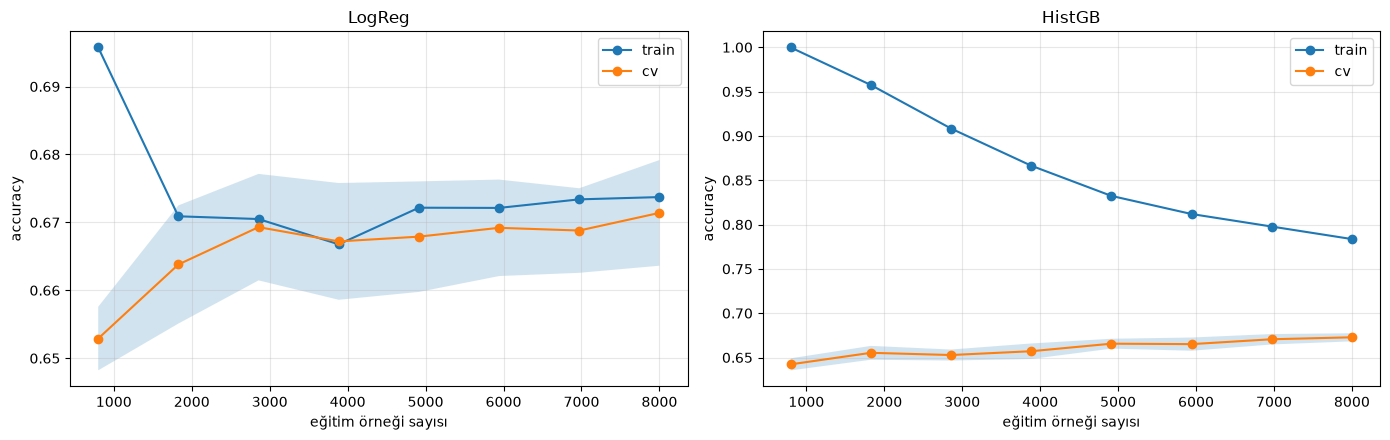

LogReg                  HistGB                
  n_train   train      cv n_train   train      cv
0     800  0.6958  0.6529     800  0.9998  0.6423
1    1828  0.6709  0.6638    1828  0.9574  0.6553
2    2857  0.6705  0.6693    2857  0.9083  0.6528
3    3885  0.6668  0.6672    3885  0.8664  0.6571
4    4914  0.6722  0.6679    4914  0.8323  0.6656
5    5942  0.6721  0.6692    5942  0.8119  0.6651
6    6971  0.6734  0.6688    6971  0.7977  0.6706
7    8000  0.6737  0.6714    8000  0.7836  0.6728

In [6]:
sizes = np.linspace(0.1, 1.0, 8)
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
curves = {}
for ax, name in zip(axes, ["LogReg", "HistGB"]):
    m, kind = models[name]
    n, tr_s, va_s = learning_curve(m, select_features(X, kind), y, cv=cv5, train_sizes=sizes, n_jobs=-1)
    curves[name] = pd.DataFrame({"n_train": n, "train": tr_s.mean(1), "cv": va_s.mean(1)}).round(4)
    ax.plot(n, tr_s.mean(1), "o-", label="train")
    ax.plot(n, va_s.mean(1), "o-", label="cv")
    ax.fill_between(n, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), alpha=0.2)
    ax.set_title(name); ax.set_xlabel("eğitim örneği sayısı"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
pd.concat(curves, axis=1)

## 3. Hata analizi

### 3a. 30. turdaki bayılma sayılarına göre P1 kazanma oranı
Bir hücrede savaş sayısı yüksek ve oran 0/1'den uzaksa, o savaşlar 30. turdaki duruma bakılarak **bilinemez**.

In [7]:
d = X.assign(y=y)
tab = d.groupby(["p1_fainted", "p2_fainted"]).y.agg(["mean", "count"])
tab = tab[tab["count"] >= 30].round(3)
tab

mean  count
p1_fainted p2_fainted              
0          0           0.606   2441
1          0           0.507   1850
           1           0.628    795
2          0           0.418   1112
           1           0.550    838
           2           0.708    243
3          0           0.327    588
           1           0.436    537
           2           0.530    296
           3           0.649     57
4          0           0.191    230
           1           0.307    274
           2           0.391    184
           3           0.646     82
5          0           0.091     99
           1           0.195    113
           2           0.250     84
           3           0.281     57

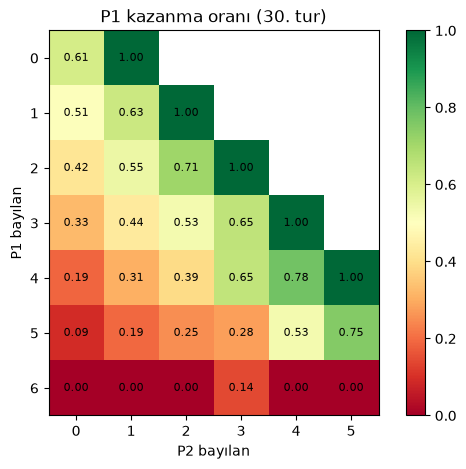

In [8]:
pivot = d.pivot_table(index="p1_fainted", columns="p2_fainted", values="y", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(pivot.columns)), pivot.columns); ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel("P2 bayılan"); ax.set_ylabel("P1 bayılan"); ax.set_title("P1 kazanma oranı (30. tur)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        if not np.isnan(pivot.values[i, j]):
            ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.show()

**Bulgular**
- 5'e 0 gerideyken bile P1 %9 kazanıyor → muhtemelen forfeit / timeout → **bilinemez (Tür A)**.
- Bayılma sayıları **eşitken** P1 %60–70 kazanıyor, %50 değil → modelde olmayan bir P1 avantajı var → **hipotez (Tür B)**.

### 3b. Modelin emin olup yanıldığı savaşlar

In [9]:
from sklearn.model_selection import cross_val_predict

m, kind = models["LogReg"]
proba = cross_val_predict(m, select_features(X, kind), y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                          method="predict_proba")[:, 1]
err = pd.DataFrame({"p1_win_proba": proba, "player_won": y}, index=X.index)
err["wrong"] = (err.p1_win_proba > 0.5) != err.player_won
err["confidence"] = (err.p1_win_proba - 0.5).abs()

print("Yanlış tahmin oranı:", err.wrong.mean().round(4))
print("Model ≥%90 emin olduğunda doğruluk:", (~err[err.confidence >= 0.4].wrong).mean().round(4),
      " (", (err.confidence >= 0.4).sum(), "savaş )")
print("Model ≤%60 emin olduğunda doğruluk:", (~err[err.confidence <= 0.1].wrong).mean().round(4),
      " (", (err.confidence <= 0.1).sum(), "savaş )")

confident_wrong = err[err.wrong].sort_values("confidence", ascending=False)
confident_wrong.head(15).join(X[["p1_fainted", "p2_fainted", "diff_hp_total", "p2_seen"]]).round(3)

Yanlış tahmin oranı: 0.3286
Model ≥%90 emin olduğunda doğruluk: 0.9359  ( 515 savaş )
Model ≤%60 emin olduğunda doğruluk: 0.5408  ( 3297 savaş )


,p1_win_proba,player_won,wrong,confidence,p1_fainted,p2_fainted,diff_hp_total,p2_seen
battle_id,,,,,,,,
1564,0.961,0,True,0.461,1,1,0.870,6
7989,0.046,1,True,0.454,5,0,-3.118,5
3267,0.048,1,True,0.452,3,0,-3.000,4
680,0.951,0,True,0.451,0,0,3.290,5
4487,0.054,1,True,0.446,5,0,-2.990,6
1636,0.056,1,True,0.444,4,0,-3.380,6
5952,0.057,1,True,0.443,3,0,-3.470,5
7242,0.060,1,True,0.440,4,0,-3.187,6
4517,0.937,0,True,0.437,0,0,0.100,5


In [10]:
def show_battle(bid, df=train):
    tl = df.set_index("battle_id").loc[bid, "battle_timeline"]
    rows = []
    for t in tl:
        a, b = t["p1_pokemon_state"], t["p2_pokemon_state"]
        boosts = lambda s: {k: v for k, v in s["boosts"].items() if v}
        rows.append({"turn": t["turn"],
                     "p1": a["name"], "p1_hp": round(a["hp_pct"], 2), "p1_status": a["status"], "p1_boost": boosts(a) or "",
                     "p1_move": t["p1_move_details"]["name"] if t["p1_move_details"] else "—",
                     "p2": b["name"], "p2_hp": round(b["hp_pct"], 2), "p2_status": b["status"], "p2_boost": boosts(b) or "",
                     "p2_move": t["p2_move_details"]["name"] if t["p2_move_details"] else "—"})
    return pd.DataFrame(rows).set_index("turn")

### 3c. Savaş 7989 (okundu — Tür A)
Model P1'e ~%3 şans verdi, **P1 kazandı**. 30. turda P1'in 5 Pokémon'u bayılmış, sadece felçli Starmie kalmış; P2'nin hiç bayılanı yok, Snorlax Belly Drum ile +6 atk. → Büyük ihtimalle P2 forfeit/timeout. Veride ipucu yok.

In [11]:
show_battle(7989)

,p1,p1_hp,p1_status,p1_boost,p1_move,p2,p2_hp,p2_status,p2_boost,p2_move
turn,,,,,,,,,,
1,forretress,0.59,nostatus,,toxic,marowak,1.00,tox,,earthquake
2,forretress,0.65,nostatus,,spikes,marowak,0.94,tox,{'atk': 2},swordsdance
3,forretress,0.00,fnt,,spikes,marowak,0.94,tox,{'atk': 2},earthquake
4,starmie,1.00,nostatus,,—,marowak,0.94,tox,{'atk': 2},earthquake
5,starmie,1.00,nostatus,,hydropump,starmie,0.94,nostatus,,—
6,starmie,1.00,nostatus,,thunderbolt,starmie,0.45,nostatus,,rapidspin
7,starmie,1.00,nostatus,,thunderbolt,dragonite,0.86,nostatus,,—
8,starmie,1.00,par,,icebeam,dragonite,0.09,nostatus,,thunderwave
9,starmie,1.00,par,,thunderbolt,dragonite,0.88,slp,,rest


### Okuma şablonu (sonraki savaşlar için)
Her savaş için: **(1)** 30. turda kim önde görünüyor? **(2)** Sonuç neden ters dönmüş olabilir? **(3)** Tür A (bilinemez) mı, Tür B (veride var, modelde yok) mı?
Bulguları `UPDATES.md` → "Hata analizi notları" bölümüne ekle.